# Data Mining Capstone Project: Philippine Household Personal Care Expenditure Analysis
**Author:** Trisha A. Biglete  
**Course:** Data Mining Capstone  
**Dataset:** Filipino Family Income and Expenditure Survey (PSA / Kaggle)  
**Primary Goal:** Classify Philippine households into High vs. Low Personal Care & Lifestyle Spenders using Machine Learning models.

## Step 1: Environment Setup & Data Loading
Mounting Google Drive and reading the raw Philippine Statistics Authority (PSA) FIES dataset.

In [1]:
import os
import pandas as pd
import numpy as np

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
target_filename = 'Family Income and Expenditure.csv'
file_path = None

In [4]:
for root, dirs, files in os.walk('/content/drive'):
    if target_filename in files:
        file_path = os.path.join(root, target_filename)
        break

if file_path:
    print(f"File successfully located at: {file_path}")
    df = pd.read_csv(file_path)
    print(f"Dataset Dimensions: {df.shape[0]} rows, {df.shape[1]} columns")
else:
    print("Error: File not found in Google Drive. Please verify the filename.")

File successfully located at: /content/drive/MyDrive/BSCS-Biglete/3rd Year/Data Mining/DataMining_FinCapstone_Biglete/Family Income and Expenditure.csv
Dataset Dimensions: 41544 rows, 60 columns


## Step 2: Data Understanding & Feature Inspection
Inspecting available spending features, specifically focusing on 'Miscellaneous Goods and Services Expenditure' (which includes personal care, cosmetics, and toiletries) to determine the distribution and target threshold.

In [5]:
spending_cols = [c for c in df.columns if 'Expenditure' in c or 'Goods' in c or 'Care' in c]

print("--- Identified Expenditure & Lifestyle Features ---")
for col in spending_cols:
    print(f"- {col}")

print("\n--- Summary Statistics for Personal Care & Lifestyle Spend ---")

target_spend_col = 'Miscellaneous Goods and Services Expenditure'

if target_spend_col in df.columns:
    print(df[target_spend_col].describe())
else:
    print(f"Column '{target_spend_col}' not found. Please check column list above.")

--- Identified Expenditure & Lifestyle Features ---
- Total Food Expenditure
- Bread and Cereals Expenditure
- Total Rice Expenditure
- Meat Expenditure
- Total Fish and  marine products Expenditure
- Fruit Expenditure
- Vegetables Expenditure
- Restaurant and hotels Expenditure
- Alcoholic Beverages Expenditure
- Tobacco Expenditure
- Clothing, Footwear and Other Wear Expenditure
- Housing and water Expenditure
- Medical Care Expenditure
- Transportation Expenditure
- Communication Expenditure
- Education Expenditure
- Miscellaneous Goods and Services Expenditure
- Special Occasions Expenditure

--- Summary Statistics for Personal Care & Lifestyle Spend ---
count     41544.000000
mean      12522.071635
std       17547.027921
min           0.000000
25%        3792.000000
50%        6804.000000
75%       14154.000000
max      553560.000000
Name: Miscellaneous Goods and Services Expenditure, dtype: float64


## Step 3: Feature Engineering & Target Classification
Engineering the binary target variable 'Spending_Tier' using the median expenditure (₱6,804.00) as the split point (1 = High Spender, 0 = Low Spender) and selecting 15 relevant socio-economic attributes.

In [6]:
target_col = 'Miscellaneous Goods and Services Expenditure'
spending_median = df[target_col].median()

In [7]:
df['Spending_Tier'] = (df[target_col] >= spending_median).astype(int)

In [8]:
desired_features = [
    'Region',
    'Total Household Income',
    'Total Food Expenditure',
    'Clothing, Footwear and Other Wear Expenditure',
    'Education Expenditure',
    'Communication Expenditure',
    'Transportation Expenditure',
    'Restaurant and hotels Expenditure',
    'Special Occasions Expenditure',
    'Medical Care Expenditure',
    'Housing and water Expenditure',
    'Household Head Age',
    'Family Members',
    'age less than 5',
    'employed'
]

In [9]:
selected_features = []
for feat in desired_features:
    matches = [c for c in df.columns if feat.lower() in c.lower()]
    if matches:
        selected_features.append(matches[0])

# Add Target Variable
df_subset = df[selected_features + ['Spending_Tier']].copy()

print(f"Target Threshold (Median): ₱{spending_median:,.2f}")
print(f"Selected {len(selected_features)} features successfully!")
print("\n--- Target Class Balance ---")
print(df_subset['Spending_Tier'].value_counts(normalize=True).map(lambda n: f"{n:.2%}"))
print(f"\nSubset Shape: {df_subset.shape[0]} rows, {df_subset.shape[1]} columns")

Target Threshold (Median): ₱6,804.00
Selected 15 features successfully!

--- Target Class Balance ---
Spending_Tier
1    50.04%
0    49.96%
Name: proportion, dtype: object

Subset Shape: 41544 rows, 16 columns


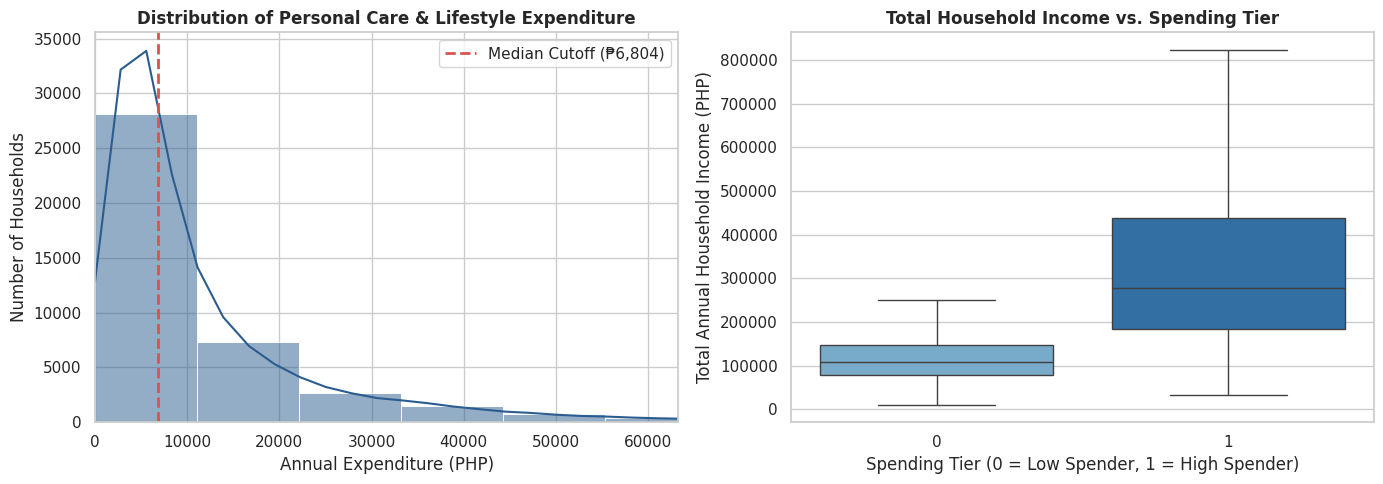

In [15]:
import os
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure the images folder exists
os.makedirs('images', exist_ok=True)

# Set clean visual style
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Distribution of Personal Care & Lifestyle Expenditure (with Median Cutoff)
sns.histplot(
    data=df,
    x='Miscellaneous Goods and Services Expenditure',
    bins=50,
    kde=True,
    color='#2b5c8f',
    ax=axes[0]
)
axes[0].axvline(6804, color='#d9534f', linestyle='--', linewidth=2, label='Median Cutoff (₱6,804)')
axes[0].set_xlim(0, df['Miscellaneous Goods and Services Expenditure'].quantile(0.98))  # Trim top 2% extreme outliers for readability
axes[0].set_title('Distribution of Personal Care & Lifestyle Expenditure', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Annual Expenditure (PHP)')
axes[0].set_ylabel('Number of Households')
axes[0].legend()

# Plot 2: Total Household Income by Spending Tier (Boxplot without extreme outliers)
sns.boxplot(
    data=df,
    x='Spending_Tier',
    y='Total Household Income',
    hue='Spending_Tier',
    palette=['#6baed6', '#2171b5'],
    legend=False,
    showfliers=False,
    ax=axes[1]
)
axes[1].set_title('Total Household Income vs. Spending Tier', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Spending Tier (0 = Low Spender, 1 = High Spender)')
axes[1].set_ylabel('Total Annual Household Income (PHP)')

plt.tight_layout()
plt.savefig('images/eda_distributions.png', dpi=300, bbox_inches='tight')
plt.show()

## Step 4: Data Quality Audit & Preprocessing
Checking for missing values, applying One-Hot Encoding to categorical variables (Region), and standardizing numerical features using 'StandardScaler'.

In [10]:
from sklearn.preprocessing import StandardScaler
import pandas as pd
import numpy as np

# 1. Audit missing values
print("--- Missing Values Audit ---")
missing_summary = df_subset.isnull().sum()
print(missing_summary[missing_summary > 0] if missing_summary.sum() > 0 else "No missing values found!")

# 2. Separate Features (X) and Target (y)
X = df_subset.drop(columns=['Spending_Tier'])
y = df_subset['Spending_Tier']

# 3. One-Hot Encode Categorical Features (Region)
X_encoded = pd.get_dummies(X, columns=['Region'], drop_first=True)

# 4. Standardize Numerical Features (Z-score Scaling)
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X_encoded), columns=X_encoded.columns)

print(f"\nPreprocessing Complete!")
print(f"Features Shape after One-Hot Encoding: {X_scaled.shape[0]} rows, {X_scaled.shape[1]} columns")

--- Missing Values Audit ---
No missing values found!

Preprocessing Complete!
Features Shape after One-Hot Encoding: 41544 rows, 30 columns


In [11]:
# Export cleaned dataset to local session and Google Drive
cleaned_filename = 'fies_cleaned_processed.csv'

# Save to local session (for quick downloading/Orange import)
df_subset.to_csv(cleaned_filename, index=False)

# Save directly to your Google Drive capstone folder
drive_export_path = f"/content/drive/MyDrive/BSCS-Biglete/3rd Year/Data Mining/DataMining_FinCapstone_Biglete/{cleaned_filename}"
df_subset.to_csv(drive_export_path, index=False)

print(f"Cleaned dataset saved successfully as '{cleaned_filename}'!")

Cleaned dataset saved successfully as 'fies_cleaned_processed.csv'!


## Step 5: Multi-Model Implementation & Evaluation
Splitting data into an 80/20 train-test split and evaluating four classification algorithms (Random Forest, Decision Tree, k-NN, Naïve Bayes) using Accuracy, Precision, Recall, and F1-Score.

In [12]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

# 1. Split data (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.20, random_state=42, stratify=y)

# 2. Define candidate models
models = {
    'Decision Tree': DecisionTreeClassifier(max_depth=10, random_state=42),
    'k-NN': KNeighborsClassifier(n_neighbors=7),
    'Naïve Bayes': GaussianNB(),
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=12, random_state=42)
}

# 3. Train and evaluate each model
results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1-Score': f1_score(y_test, y_pred)
    })

# 4. Display comparison table
comparison_df = pd.DataFrame(results).sort_values(by='F1-Score', ascending=False).reset_index(drop=True)
print("=== MODEL PERFORMANCE COMPARISON ===")
print(comparison_df.to_string(index=False))

=== MODEL PERFORMANCE COMPARISON ===
        Model  Accuracy  Precision   Recall  F1-Score
Random Forest  0.843062   0.849584 0.834055  0.841748
Decision Tree  0.812733   0.813645 0.811688  0.812666
         k-NN  0.810687   0.847540 0.758057  0.800305
  Naïve Bayes  0.770490   0.889581 0.618086  0.729388


## Step 6: Feature Importance & Model Evaluation Plots
Generating feature importance rankings and the Confusion Matrix heatmap for the top-performing model (Random Forest) and saving the output images for GitHub documentation.

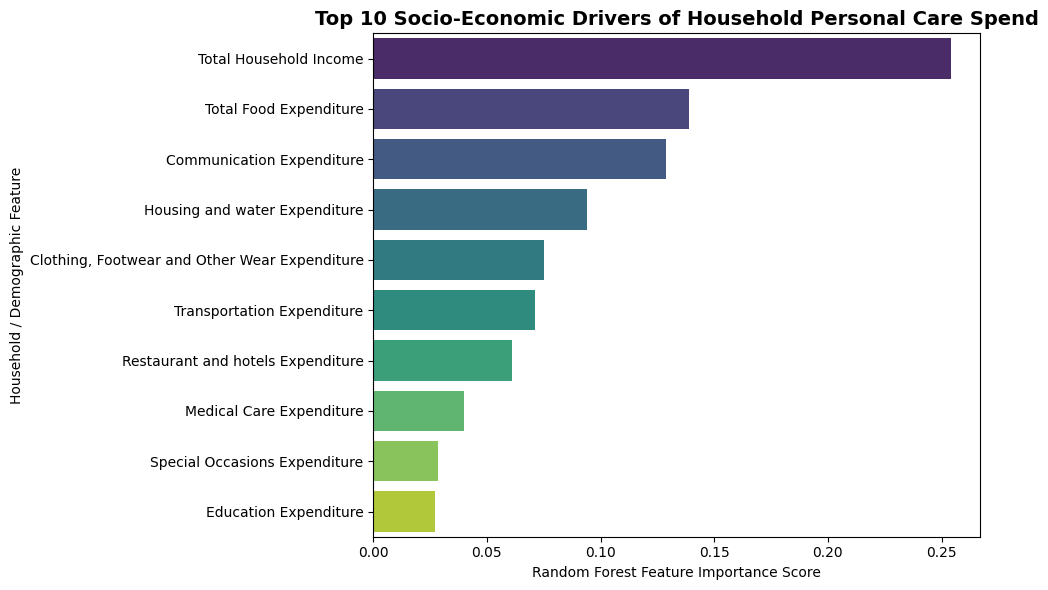

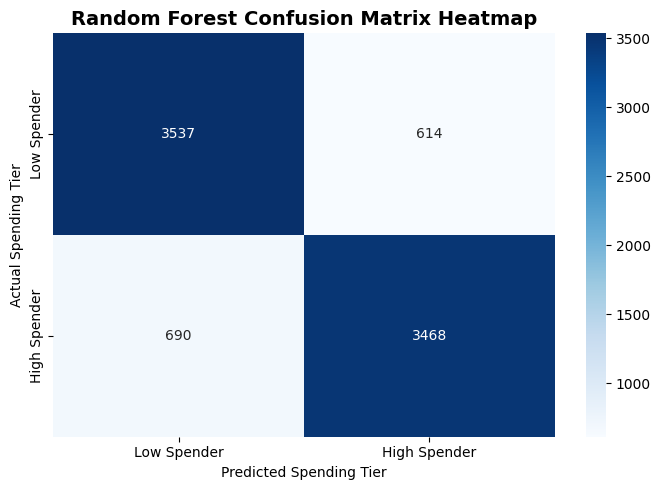


Visualizations saved cleanly to 'images/feature_importance.png' and 'images/confusion_matrix.png'!


In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import os

# Ensure local images directory exists
os.makedirs('images', exist_ok=True)

# 1. Feature Importance Plot (Warning Fixed)
rf_winning_model = models['Random Forest']
importances = rf_winning_model.feature_importances_
feature_names = X_scaled.columns

feature_imp_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False).head(10)

plt.figure(figsize=(10, 6))
sns.barplot(
    x='Importance',
    y='Feature',
    data=feature_imp_df,
    hue='Feature',
    legend=False,
    palette='viridis'
)
plt.title('Top 10 Socio-Economic Drivers of Household Personal Care Spend', fontsize=14, fontweight='bold')
plt.xlabel('Random Forest Feature Importance Score')
plt.ylabel('Household / Demographic Feature')
plt.tight_layout()
plt.savefig('images/feature_importance.png', dpi=300)
plt.show()

# 2. Confusion Matrix Heatmap
plt.figure(figsize=(7, 5))
y_pred_rf = rf_winning_model.predict(X_test)
cm_rf = confusion_matrix(y_test, y_pred_rf)

sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Low Spender', 'High Spender'],
            yticklabels=['Low Spender', 'High Spender'])
plt.title('Random Forest Confusion Matrix Heatmap', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Spending Tier')
plt.ylabel('Actual Spending Tier')
plt.tight_layout()
plt.savefig('images/confusion_matrix.png', dpi=300)
plt.show()

print("\nVisualizations saved cleanly to 'images/feature_importance.png' and 'images/confusion_matrix.png'!")

## Step 7: Live BigQuery SQL Data Acquisition Pipeline (Bonus Feature)
Executing SQL query directly in Google BigQuery to categorize household spending tiers and loading results into Colab.

In [16]:
# Code Block 7: Live BigQuery SQL Pipeline (Bonus +4 Points)

from google.colab import auth
from google.cloud import bigquery
import pandas as pd

# 1. Authenticate Google Cloud account
auth.authenticate_user()

# 2. Initialize BigQuery client
project_id = 'datamining-fincapstone-biglete'
client = bigquery.Client(project=project_id)

# 3. Define SQL Query using BigQuery's sanitized V2 column names
sql_query = f"""
    SELECT
      Region,
      `Total Household Income` AS Total_Income,
      `Clothing_ Footwear and Other Wear Expenditure` AS Clothing_Spend,
      `Communication Expenditure` AS Communication_Spend,
      `Miscellaneous Goods and Services Expenditure` AS Personal_Care_Spend,
      CASE
        WHEN `Miscellaneous Goods and Services Expenditure` >= 6804 THEN 'High Spender'
        ELSE 'Low Spender'
      END AS Spending_Tier
    FROM
      `{project_id}.fies_data.household_expenditure`
    LIMIT 10
"""

# 4. Fetch query results into Pandas
df_bq = client.query(sql_query).to_dataframe()

print("=== BIGQUERY SQL PIPELINE SUCCESSFUL ===")
print(df_bq)

=== BIGQUERY SQL PIPELINE SUCCESSFUL ===
  Region  Total_Income  Clothing_Spend  Communication_Spend  \
0    CAR        480332            4607                 2880   
1    CAR        198235            8230                 5700   
2    CAR         82785            2735                  420   
3    CAR        107589            1390                  660   
4    CAR        189322            4620                 2100   
5    CAR        152883            1930                 1500   
6    CAR        198621            7930                 1848   
7    CAR        134961            4085                 3000   
8    CAR        171152            2780                 1800   
9    CAR        625753            7740                 7200   

   Personal_Care_Spend Spending_Tier  
0                34056  High Spender  
1                 9150  High Spender  
2                 6450   Low Spender  
3                 3762   Low Spender  
4                 8472  High Spender  
5                 5394   Low Sp